# Thermal network of a box-type solar cooker — Part 1

## 1. Tools

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import pandas as pd
from scipy.interpolate import interp1d
import datetime

# --- Some data
sigma = 5.670e-8      # Stefan-Boltzmann constant, W/(m2 K4)
K0 = 273.15           # 0 degC in K

## 2. Site, design day and weather

Louvain-la-Neuve, 24 June 2020, cooking from 11:30 local standard time. Firstly, the weather data from 2020 were obtained through the EPW file coming from the nearest weather station, Beauvechain Air Base. The data were then extracted from the file to keep the ones related to the 24th June of 2020. There was a focus on the DNI (direct normal irradiance [W/m2]), DHI (diffuse horizontal irradiance [W/m2]), GHI (global horizontal irradiance [W/m2]), Ta (ambiant temperature [°C]), Tdp (dew point temperature [°C]) and V (wind speed [m/s]).

Secondly, a function was created to convert an hour given in local standard time into an hour in solar time (and vice versa) via the following equations :  

$$t_{sol} - t_{std} = 4\,(L_{st} - L_{loc}) + E_t$$  
with $t_{sol}$, the solar time [h]  
$t_{std}$, the standard time [h]  
$L_{st}$, the standard meridian of the time zone [°C West]  
     $L_{loc}$, the local longitude [°C West]  

where $E_t$ is calculated as :

$$E_t = 229.2\,(0.000075 + 0.001868\cos B - 0.032077\sin B - 0.014615\cos 2B - 0.04089\sin 2B)$$

and where $B$ is calculated as :

$$B = (n - 1)\,\frac{360}{365}$$
with $n$, the number of the day [-]  

Thirdly, as the weather values correspond to a mean during the one-hour timestep ending, we suppose the data in the middle of the one-hour timestamp equals the mean at the hour ending the timestep. An interpolation was made between these data. A function was then created to compute the DNI, DHI, GHI, Ta, Tdp and V at any moment during the cooking window. This fonction gives these values under the form of a dictionnary.

176
{'G_bn': array([821. , 821.2, 821.4, 821.6, 821.8, 822. , 822.2, 822.4, 822.6,
       822.8, 823. , 822. , 821. , 820. , 819. , 818. , 817. , 816. ,
       815. , 814. , 813. , 810.7, 808.4, 806.1]), 'G_d': array([134. , 134.1, 134.2, 134.3, 134.4, 134.5, 134.6, 134.7, 134.8,
       134.9, 135. , 134.7, 134.4, 134.1, 133.8, 133.5, 133.2, 132.9,
       132.6, 132.3, 132. , 131.4, 130.8, 130.2]), 'G': array([852. , 852.9, 853.8, 854.7, 855.6, 856.5, 857.4, 858.3, 859.2,
       860.1, 861. , 857.4, 853.8, 850.2, 846.6, 843. , 839.4, 835.8,
       832.2, 828.6, 825. , 817.2, 809.4, 801.6]), 'Ta': array([23.2 , 23.35, 23.5 , 23.65, 23.8 , 23.95, 24.1 , 24.25, 24.4 ,
       24.55, 24.7 , 24.69, 24.68, 24.67, 24.66, 24.65, 24.64, 24.63,
       24.62, 24.61, 24.6 , 24.64, 24.68, 24.72]), 'Tdp': array([11.4 , 11.57, 11.74, 11.91, 12.08, 12.25, 12.42, 12.59, 12.76,
       12.93, 13.1 , 12.99, 12.88, 12.77, 12.66, 12.55, 12.44, 12.33,
       12.22, 12.11, 12.  , 12.14, 12.28, 12.42]), 'V': ar

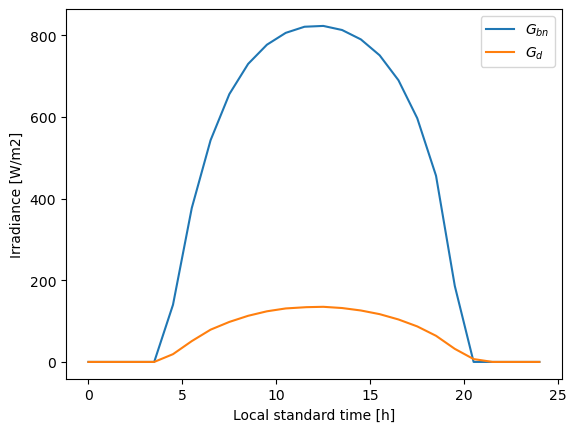

In [2]:
# --- site: Louvain-la-Neuve (as in the slides)
phi_deg = 50.67     # latitude, deg (north positive)
Lloc = 355.39       # in ° W
Lst = 345           # in ° W

# --- determination of the number of the day
def day_of_year(year, month, day):
    d = datetime.date(year, month, day)
    return d.timetuple().tm_yday

# --- design day + calculation of B
EPW_name = "BEL_VLG_Beauvechain.AP.064580_TMYx.2011-2025.epw"
year = 2020
month = 6
day = 24
n_day = day_of_year(year, month, day)
B = (n_day-1)*360/365
print(n_day)

# --- conversion solar time - standard time
def standard_time_to_solar_time(t_standard_time, summer_time=False, reverse=False): # False because EPW don't take into account summer time
  """converts an hour given in (local) standard time into an hour in solar time, t in hours"""
  Et = 229.2*(0.000075+0.001868*np.cos(np.radians(B))-0.032077*np.sin(np.radians(B))-0.014615*np.cos(np.radians(2*B))-0.04089*np.sin(np.radians(2*B)))
  if summer_time == True:
      summer = 1 # we add/remove 1 hour if we are in summer time
  else:
      summer = 0
  if reverse == False:
      t_solar_time = t_standard_time + (4*(Lst-Lloc) + Et)/60 - summer
      return t_solar_time
  if reverse == True:
      t_solar_time = t_standard_time # argument in the fonction is the standard time then
      t_standard_time = t_solar_time - (4*(Lst-Lloc) + Et)/60 + summer
      return t_standard_time


# --- cooking window
t_start_h = 11.5  # start of cooking, h (local standard time)
t_end_h   = 13.75 # end of the simulation, h (local standard time)
dt = 0.1
t_cooking_window = np.arange(t_start_h, t_end_h + dt, dt) # h (local standard time)

# --- extraction of the data from the EPW file + function giving a dictionnary through time interpolation
EPW = pd.read_csv(EPW_name, skiprows=8, header=None)
columns = [
    "Year", "Month", "Day", "Hour", "Minute",
    "Data_Source_Uncertainty_Flags", "Dry_Bulb_Temperature", "Dew_Point_Temperature",
    "Relative_Humidity", "Atmospheric_Station_Pressure", "Extraterrestrial_Horizontal_Radiation",
    "Extraterrestrial_Direct_Normal_Radiation", "Horizontal_Infrared_Radiation_from_Sky",
    "Global_Horizontal_Radiation", "Direct_Normal_Radiation", "Diffuse_Horizontal_Radiation",
    "Global_Horizontal_Illuminance", "Direct_Normal_Illuminance", "Diffuse_Horizontal_Illuminance",
    "Zenith_Luminance", "Wind_Direction", "Wind_Speed", "Total_Sky_Cover", "Opaque_Sky_Cover",
    "Visibility", "Ceiling_Height", "Present_Weather_Observation", "Present_Weather_Codes",
    "Precipitable_Water", "Aerosol_Optical_Depth", "Snow_Depth", "Days_Since_Last_Snow",
    "Albedo", "Liquid_Precipitation_Quantity", "Liquid_Precipitation_Time"
]

EPW.columns = columns

EPW = EPW[(EPW["Year"] == year) & (EPW["Month"] == month) & (EPW["Day"] == day)]

DNI_EPW = EPW["Direct_Normal_Radiation"].tolist() # direct normal irradiance in W/m2 (because during 1 hour)
DHI_EPW = EPW["Diffuse_Horizontal_Radiation"].tolist() # diffuse horizontal irradiance in W/m2 (because during 1 hour)
GHI_EPW = EPW["Global_Horizontal_Radiation"].tolist() # global horizontal irradiance in W/m2 (because during 1 hour)
Ta_EPW = EPW["Dry_Bulb_Temperature"].tolist() # ambiant temperature in °C
Tdp_EPW = EPW["Dew_Point_Temperature"].tolist() # dew point temperature in °C
V_EPW = EPW["Wind_Speed"].tolist() # wind speed in m/s
time_EPW = np.arange(0.5, 24.5, 1) # we suppose the "mean" values are the middle values of the one-hour timestep

DNI_f = interp1d(time_EPW, DNI_EPW, fill_value="extrapolate")
DHI_f = interp1d(time_EPW, DHI_EPW, fill_value="extrapolate")
GHI_f = interp1d(time_EPW, GHI_EPW, fill_value="extrapolate")
Ta_f = interp1d(time_EPW, Ta_EPW, fill_value="extrapolate")
Tdp_f = interp1d(time_EPW, Tdp_EPW, fill_value="extrapolate")
V_f = interp1d(time_EPW, V_EPW, fill_value="extrapolate")

def weather(t_local_standard_time):
    """EPW values according to local standard time. Returns a dictionary."""
    DNI = DNI_f(t_local_standard_time)
    DHI = DHI_f(t_local_standard_time)
    GHI = GHI_f(t_local_standard_time)
    Ta = Ta_f(t_local_standard_time)
    Tdp = Tdp_f(t_local_standard_time)
    V = V_f(t_local_standard_time)
    return dict(G_bn=DNI, G_d=DHI, G=GHI, Ta=Ta, Tdp=Tdp, V=V)

print(weather(t_cooking_window)) # extraction of weather values during cooking window time stamp

# --- Graph showing Gbn and Gd according to time
one_day = np.arange(0,24.1,0.1)
Gbn_graph = [weather(t)["G_bn"] for t in one_day]
Gd_graph  = [weather(t)["G_d"]  for t in one_day]

print(max(Gbn_graph))
print(max(Gd_graph))

plt.plot(one_day, Gbn_graph, label=r"$G_{bn}$")
plt.plot(one_day, Gd_graph, label=r"$G_d$")

plt.xlabel("Local standard time [h]")
plt.ylabel(r"Irradiance [W/m2]")
plt.legend()

plt.show()

## 4. Sun position

The sun postion is determined via the zenith angle $\theta_z$ [°] and the azimuth angle $\gamma_s$ [°]. In order to calculate these values, the declination angle $\delta$ [°] and the hour angle $\omega$ [°] were first determined.
$$
\delta = 23.45\sin\!\left( 360\,\frac{284 + n}{365} \right)
$$

$$
\omega = 15(t_{sol} - 12)
$$

Then, $\theta_z$ is computed :

$$
\theta_z = \arccos\!\left(
\cos\phi\,\cos\delta\,\cos\omega + \sin\phi\,\sin\delta
\right)
$$

Finally, knowing each angle, $\gamma_s$ can be calculated :
$$
\gamma_s = \operatorname{sign}(\omega)\,
\left|\arccos\!\left(
\frac{\cos\theta_z\,\sin\phi - \sin\delta}{\sin\theta_z\,\cos\phi}
\right)\right|
$$

[30.79527825 30.27346498 29.78739098 29.3389677  28.93006984 28.56250727
 28.23799458 27.95811904 27.72430818 27.53779831 27.39960535 27.31049965
 27.2709861  27.28129063 27.3413542  27.45083435 27.60911442 27.81531976
 28.06834    28.36685607 28.70937046 29.09423933 29.51970487 29.98392684]
[-34.54178243 -32.03418043 -29.46042193 -26.82220395 -24.12204006
 -21.36331423 -18.55031359 -15.68823452 -12.78315734  -9.84198632
  -6.87235396  -3.88249098  -0.8810664    2.12299536   5.12071112
   8.10323878  11.06206951  13.98920213  16.87729141  19.7197642
  22.51090045  25.24587859  27.92078732  30.53260788]
27.27098609519746
-179.58019086389788
-169.59711781056413


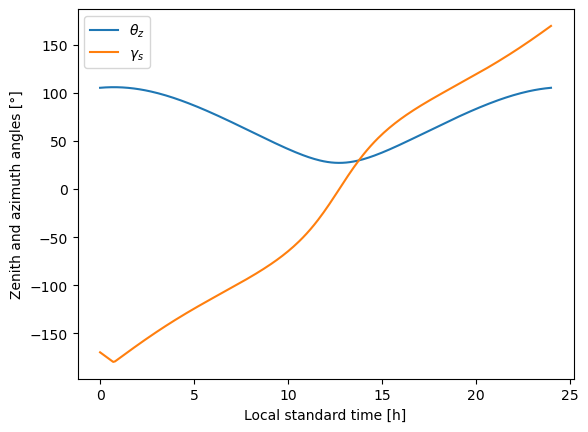

In [3]:
# --- declination angle (degrees)
delta_deg = 23.45 * np.sin(np.radians(360 * (284 + n_day) / 365))   # declination, deg

# --- hour angle (degrees)
def w_deg(t_local_standard_time):
    """Compute w (hour angle) in degrees for each local standard time"""
    t_solar_time = standard_time_to_solar_time(t_local_standard_time)
    w_deg = 15.0 * (t_solar_time - 12.0)
    return w_deg

# --- zenith angle (degrees)
def theta_z_deg(t_local_standard_time):
    """Compute theta_z in degrees for each local standard time"""
    phi = np.radians(phi_deg)
    delta = np.radians(delta_deg)
    w = np.radians(w_deg(t_local_standard_time))

    theta_z = np.arccos(np.cos(phi)*np.cos(delta)*np.cos(w) + np.sin(phi)*np.sin(delta))
    return np.degrees(theta_z)

# --- solar azimuth angle (degrees)
def gamma_s_deg(t_local_standard_time):
    """Compute gamma_s (solar azimuth) in degrees for each local standard time"""
    theta_z = np.radians(theta_z_deg(t_local_standard_time))
    phi = np.radians(phi_deg)
    delta = np.radians(delta_deg)
    w = np.radians(w_deg(t_local_standard_time))

    num = np.cos(theta_z) * np.sin(phi) - np.sin(delta)
    den = np.sin(theta_z) * np.cos(phi)
    arg = num / den

    gamma_s = np.sign(w) * np.abs(np.arccos(arg))
    return np.degrees(gamma_s)

print(theta_z_deg(t_cooking_window))
print(gamma_s_deg(t_cooking_window))

# --- Graph showing the zenith angle and the azimuth angle according to time
one_day = np.arange(0,24.1,0.1)
zenith_angle_graph = theta_z_deg(one_day)
azimuth_angle_graph  = gamma_s_deg(one_day)

print(min(zenith_angle_graph))
print(min(azimuth_angle_graph))
print(gamma_s_deg(0))

plt.plot(one_day, zenith_angle_graph, label=r"$\theta_z$")
plt.plot(one_day, azimuth_angle_graph, label=r"$\gamma_s$")

plt.xlabel("Local standard time [h]")
plt.ylabel("Zenith and azimuth angles [°]")
plt.legend()

plt.show()